# `vkscipy` Demo — SciPy-Compatible Scientific Computing on Vulkan GPU

Showcases `vkscipy` across all 6 submodules:
1. **`vkscipy.spatial.distance.cdist`**: 2048×2048 pairwise Euclidean & Cosine distance matrices via Vulkan GPU GEMM.
2. **`vkscipy.ndimage`**: GPU `gaussian_filter`, `sobel` edge detection, and `laplace` rendered with `vkcolorcet`.
3. **`vkscipy.signal.spectrogram`**: Batched GPU GEMM STFT power spectrogram of a multi-frequency chirp signal.
4. **`vkscipy.stats` & `vkscipy.optimize.curve_fit`**: GPU correlation matrices & nonlinear Levenberg–Marquardt curve fitting.

In [1]:
import sys, time
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
from PIL import Image, ImageDraw
import vknumpy as vnp
import vkscipy as vsp
import vkcolorcet as cc

# 1. Pairwise GPU cdist (2048 x 2048 in 64D)
rng = np.random.default_rng(42)
A = vnp.array(rng.standard_normal((2048, 64), dtype=np.float32))
B = vnp.array(rng.standard_normal((2048, 64), dtype=np.float32))
_ = vsp.spatial.distance.cdist(A, B).to_numpy()  # warmup

t0 = time.perf_counter()
D_euc = vsp.spatial.distance.cdist(A, B, metric="euclidean")
t_euc = (time.perf_counter() - t0) * 1000.0

t0 = time.perf_counter()
D_cos = vsp.spatial.distance.cdist(A, B, metric="cosine")
t_cos = (time.perf_counter() - t0) * 1000.0

print(f"GPU cdist (2048x2048, 64D) | Euclidean: {t_euc:.1f} ms | Cosine: {t_cos:.1f} ms")

# 2. GPU curve_fit on 200k noisy samples: y = a * exp(-b * x) * cos(w * x) + c
xg = vnp.linspace(0.0, 6.0, 200_000, dtype=np.float32)
noise = vnp.array(rng.normal(0.0, 0.08, size=200_000).astype(np.float32))
yg = 3.2 * vnp.exp(-0.45 * xg) * vnp.cos(2.8 * xg) + 0.7 + noise
t0 = time.perf_counter()
popt, _ = vsp.optimize.curve_fit(
    lambda x, a, b, w, c: a * vnp.exp(-b * x) * vnp.cos(w * x) + c,
    xg, yg, p0=[2.0, 0.2, 2.5, 0.0],
)
print(f"GPU curve_fit (200k pts) in {(time.perf_counter()-t0)*1000:.1f} ms | true=[3.2, 0.45, 2.8, 0.7] | fit={np.round(popt, 4)}")

ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


GPU cdist (2048x2048, 64D) | Euclidean: 18.8 ms | Cosine: 7.4 ms


GPU curve_fit (200k pts) in 2071.8 ms | true=[3.2, 0.45, 2.8, 0.7] | fit=[3.1993 0.45   2.8    0.7002]


GPU STFT spectrogram (129, 253) computed in 4.7 ms


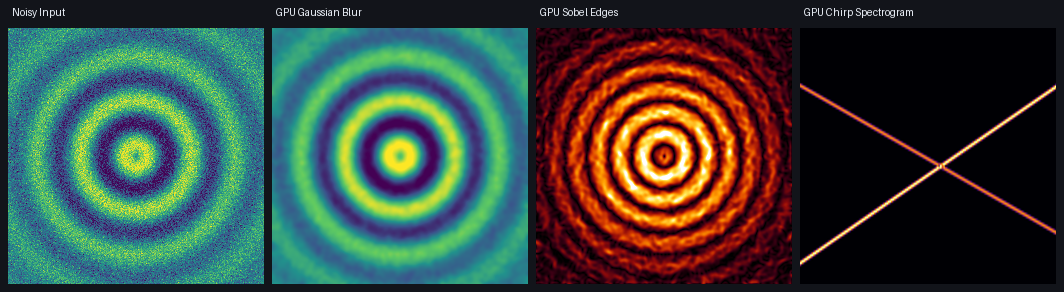

In [2]:
def _colorize(arr2d, cmap="inferno"):
    a = arr2d.to_numpy() if hasattr(arr2d, "to_numpy") else np.asarray(arr2d)
    lo, hi = float(np.percentile(a, 1)), float(np.percentile(a, 99.5))
    norm = np.clip((a - lo) / max(hi - lo, 1e-6), 0.0, 1.0)
    lut = cc.get_rgb_lut(cmap)
    rgb = lut[np.round(norm * 255.0).astype(np.int32)]
    return Image.fromarray(rgb, mode="RGB")

# 3. GPU ndimage filtering: synthetic rings + noise -> Gaussian blur -> Sobel edges
yy, xx = np.mgrid[-1.0:1.0:256j, -1.0:1.0:256j].astype(np.float32)
r = np.sqrt(xx * xx + yy * yy)
raw = np.sin(18.0 * r) * np.exp(-1.2 * r * r) + 0.25 * rng.standard_normal((256, 256)).astype(np.float32)

blur  = vsp.ndimage.gaussian_filter(raw, sigma=2.2)
edges = vsp.ndimage.sobel(blur)

# 4. GPU STFT Spectrogram of a dual-chirp signal (16,384 samples)
fs = 4096.0
t = np.linspace(0.0, 4.0, int(fs * 4.0), dtype=np.float32)
chirp = (
    np.sin(2.0 * np.pi * (150.0 * t + 180.0 * t * t))
    + 0.7 * np.sin(2.0 * np.pi * (1600.0 * t - 150.0 * t * t))
).astype(np.float32)
t0 = time.perf_counter()
freqs, times, Sxx = vsp.signal.spectrogram(chirp, fs=fs, nperseg=256, noverlap=192)
print(f"GPU STFT spectrogram {Sxx.shape} computed in {(time.perf_counter()-t0)*1000:.1f} ms")
spec_img = _colorize(np.log1p(Sxx.to_numpy()[::-1] * 500.0), cmap="inferno").resize((256, 256))

panels = [
    ("Noisy Input", _colorize(raw, "viridis")),
    ("GPU Gaussian Blur", _colorize(blur, "viridis")),
    ("GPU Sobel Edges", _colorize(edges, "fire")),
    ("GPU Chirp Spectrogram", spec_img),
]
canvas = Image.new("RGB", (4 * 264 + 8, 292), (18, 20, 26))
draw = ImageDraw.Draw(canvas)
for i, (title, im) in enumerate(panels):
    x0 = 8 + i * 264
    draw.text((x0 + 4, 6), title, fill=(235, 240, 248))
    canvas.paste(im, (x0, 28))
canvas